In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras

DATA_DIR = '/Users/ismayasmin/Documents/DWC26_project/data'
OUT_DIR = '/Users/ismayasmin/Documents/DWC26_project/outputs'

print('notebook is running in:', os.getcwd())
print(os.listdir(OUT_DIR))
print(os.listdir(DATA_DIR))

notebook is running in: /Users/ismayasmin/Documents/DWC26_project
['oil_cumulative_quarterly.csv', 'model_comparison_oil.png', 'gas_cumulative_quarterly.csv', 'water_cumulative_quarterly.csv', 'best10_settings.csv', 'case_settings.csv', 'scaling.npz', 'model_comparison_validation.csv', 'dense_model.keras']
['03_Train_Cases_1__Case_1.csv', '02 Field Production.xlsx', '01 Introduction.xlsx']


## Step a: load and prepare data

In [8]:
settings = pd.read_csv(f'{OUT_DIR}/case_settings.csv')
oil   = pd.read_csv(f'{OUT_DIR}/oil_cumulative_quarterly.csv', index_col=0, parse_dates=True)
gas   = pd.read_csv(f'{OUT_DIR}/gas_cumulative_quarterly.csv', index_col=0, parse_dates=True)
water = pd.read_csv(f'{OUT_DIR}/water_cumulative_quarterly.csv', index_col=0, parse_dates=True)

print(settings.shape, oil.shape, gas.shape, water.shape)
print('blank cells:', int(oil.isna().sum().sum() + gas.isna().sum().sum() + water.isna().sum().sum()))
print(oil[['Case_1', 'Case_90', 'Observed']].tail(2))

(100, 5) (41, 101) (41, 101) (41, 101)
blank cells: 0
                Case_1     Case_90      Observed
2007-10-01  34720492.0  37833272.0  3.789561e+07
2008-01-01  35150436.0  38378920.0  3.837832e+07


In [9]:
SETTING_COLS = ['Fault Transmissibility', 'Porosity Multiplier',
                'Permeability Multiplier', 'Aquifer Pore Volume']
case_cols = [f'Case_{i}' for i in range(1, 101)]

X = settings[SETTING_COLS].values
Y = np.hstack([oil[case_cols].T.values, gas[case_cols].T.values, water[case_cols].T.values])

train_idx, val_idx, test_idx = np.arange(0, 70), np.arange(70, 85), np.arange(85, 100)

print(X.shape, Y.shape)
print(settings['Item'].iloc[[0, 69, 70, 84, 85, 99]].tolist())

(100, 4) (100, 123)
['Case 1', 'Case 70', 'Case 71', 'Case 85', 'Case 86', 'Case 100']


In [10]:
mu, sd = X[train_idx].mean(axis=0), X[train_idx].std(axis=0)
scale = np.concatenate([np.full(41, Y[train_idx][:, k*41:(k+1)*41].max()) for k in range(3)])

def scale_X(a):
    return (a - mu) / sd

Xtr, Xva = scale_X(X[train_idx]), scale_X(X[val_idx])
Ytr, Yva = Y[train_idx] / scale, Y[val_idx] / scale

print('settings, average:', Xtr.mean(axis=0).round(2), ' spread:', Xtr.std(axis=0).round(2))
print('curves, smallest and largest:', Ytr.min().round(3), Ytr.max().round(3))

settings, average: [-0. -0. -0.  0.]  spread: [1. 1. 1. 1.]
curves, smallest and largest: 0.0 1.0


## Step b: dense neural network (benchmark)

In [11]:
keras.utils.set_random_seed(42)

dense = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(123),
])
dense.compile(optimizer='adam', loss='mse')

stop = keras.callbacks.EarlyStopping(patience=50, restore_best_weights=True)
history = dense.fit(Xtr, Ytr, validation_data=(Xva, Yva),
                    epochs=1000, batch_size=8, callbacks=[stop], verbose=0)

print('trained for', len(history.history['loss']), 'rounds')

trained for 1000 rounds


## Step c: validation errors of the benchmark

In [12]:
pred = dense.predict(Xva, verbose=0) * scale
true = Y[val_idx]

for k, fluid in enumerate(['oil', 'gas', 'water']):
    t, p = true[:, k*41:(k+1)*41], pred[:, k*41:(k+1)*41]
    whole = np.abs(p - t).sum() / t.sum() * 100
    final = np.mean(np.abs(p[:, -1] - t[:, -1]) / t[:, -1]) * 100
    print(f'{fluid}: whole-curve error {whole:.2f}% | error at 2008 {final:.2f}%')

oil: whole-curve error 1.95% | error at 2008 1.75%
gas: whole-curve error 2.08% | error at 2008 1.58%
water: whole-curve error 3.61% | error at 2008 2.54%


In [13]:
dense.save(f'{OUT_DIR}/dense_model.keras')
np.savez(f'{OUT_DIR}/scaling.npz', mu=mu, sd=sd, scale=scale)

def errors(pred, true):
    out = {}
    for k, fluid in enumerate(['oil', 'gas', 'water']):
        t, p = true[:, k*41:(k+1)*41], pred[:, k*41:(k+1)*41]
        out[f'{fluid} whole-curve %'] = np.abs(p - t).sum() / t.sum() * 100
        out[f'{fluid} at 2008 %'] = np.mean(np.abs(p[:, -1] - t[:, -1]) / t[:, -1]) * 100
    return out

results = {'dense network': errors(pred, true)}
print(pd.DataFrame(results).T.round(2))
print(os.listdir(OUT_DIR))

               oil whole-curve %  oil at 2008 %  gas whole-curve %  \
dense network               1.95           1.75               2.08   

               gas at 2008 %  water whole-curve %  water at 2008 %  
dense network           1.58                 3.61             2.54  
['oil_cumulative_quarterly.csv', 'gas_cumulative_quarterly.csv', 'water_cumulative_quarterly.csv', 'case_settings.csv', 'scaling.npz', 'dense_model.keras']


## Step d: exploration of the 3D files (CNN not built)

These cells read the CSV versions of files 03 and 07.

In [24]:
case = pd.read_csv(f'{DATA_DIR}/03_Train_Cases_1__Case_1.csv', low_memory=False)
cols = ['Pore Volume (PORV)', 'Pressure (PRESSURE)', 'Water Saturation (SWAT)',
        'Connate Water Saturation (SWL)', 'Oil Saturation (SOIL)']
for c in cols:
    case[c] = pd.to_numeric(case[c], errors='coerce')

live = case[case['Pore Volume (PORV)'] > 0]
print(len(live), 'active blocks')
print(live[cols[1:]].describe().round(3))

42512 active blocks
       Pressure (PRESSURE)  Water Saturation (SWAT)  \
count            42512.000                42512.000   
mean              4507.111                    0.801   
std                126.215                    0.337   
min               4247.211                    0.200   
25%               4403.800                    0.270   
50%               4499.803                    1.000   
75%               4601.173                    1.000   
max               4891.720                    1.000   

       Connate Water Saturation (SWL)  Oil Saturation (SOIL)  
count                       42512.000              42512.000  
mean                            0.235                  0.199  
std                             0.024                  0.337  
min                             0.200                  0.000  
25%                             0.230                  0.000  
50%                             0.230                  0.000  
75%                             0.270      

In [25]:
oil_zone = live[live['Water Saturation (SWAT)'] < 0.99]
print(len(oil_zone), 'blocks that are not fully water-filled')
print('of those, share with water above starting level:',
      round((oil_zone['Water Saturation (SWAT)'] > oil_zone['Connate Water Saturation (SWL)'] + 0.01).mean(), 3))

11004 blocks that are not fully water-filled
of those, share with water above starting level: 0.0


In [26]:
def load_grid(filename, column):
    df = pd.read_csv(f'{DATA_DIR}/{filename}', usecols=['I Index', 'J Index', 'K Index', column], low_memory=False)
    df = df.apply(pd.to_numeric, errors='coerce')
    values = df[column].where(df[column] != -999.25, 0).values        # -999.25 means no data
    grid = np.zeros((53, 55, 31))
    grid[df['I Index'].astype(int) - 1, df['J Index'].astype(int) - 1, df['K Index'].astype(int) - 1] = values
    return grid

f1, f71 = '03_Train_Cases_1__Case_1.csv', '07__Validation_Cases__Case_71.csv'

for column, setting in [('Porosity (PORO)', 1), ('Permeability I (PERMX)', 2)]:
    a, b = load_grid(f1, column), load_grid(f71, column)
    mask = (a > 0) & (b > 0)
    ratio = b[mask] / a[mask]
    print(column, '| blocks compared:', mask.sum(),
          '| ratio min / median / max:', ratio.min().round(3), np.median(ratio).round(3), ratio.max().round(3))
    print("   ratio of the two cases' settings:", (X[70, setting] / X[0, setting]).round(3))

Porosity (PORO) | blocks compared: 42512 | ratio min / median / max: 1.36 1.36 1.36
   ratio of the two cases' settings: 1.36
Permeability I (PERMX) | blocks compared: 42512 | ratio min / median / max: 0.253 1.0 1.0
   ratio of the two cases' settings: 0.253


In [27]:
a = load_grid(f1, 'Permeability I (PERMX)')
b = load_grid(f71, 'Permeability I (PERMX)')
mask = (a > 0) & (b > 0)
vals, counts = np.unique((b[mask] / a[mask]).round(3), return_counts=True)
print(dict(zip(vals, counts)))

{np.float64(0.253): np.int64(11575), np.float64(1.0): np.int64(30937)}


## Model B: PCA + Gaussian process

In [14]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.9999, svd_solver='full').fit(Ytr)
Ztr = pca.transform(Ytr)
print('PCA keeps', pca.n_components_, 'numbers per curve (instead of 123)')

# check: squeeze the validation curves down and rebuild them. how much do we lose?
rebuilt = pca.inverse_transform(pca.transform(Yva)) * scale
print(pd.Series(errors(rebuilt, Y[val_idx])).round(3))

PCA keeps 4 numbers per curve (instead of 123)
oil whole-curve %      0.043
oil at 2008 %          0.046
gas whole-curve %      0.042
gas at 2008 %          0.053
water whole-curve %    0.115
water at 2008 %        0.050
dtype: float64


In [15]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel as C, WhiteKernel

kernel = C(1.0) * RBF(length_scale=np.ones(4)) + WhiteKernel(1e-5)
gpr = GaussianProcessRegressor(kernel=kernel, normalize_y=True, n_restarts_optimizer=5, random_state=42)
gpr.fit(Xtr, Ztr)

def predict_gpr(X_raw):
    return pca.inverse_transform(gpr.predict(scale_X(X_raw))) * scale

pred_gpr = predict_gpr(X[val_idx])
results['PCA + GPR'] = errors(pred_gpr, Y[val_idx])
print(pd.DataFrame(results).T.round(2))

               oil whole-curve %  oil at 2008 %  gas whole-curve %  \
dense network               1.95           1.75               2.08   
PCA + GPR                   0.11           0.11               0.11   

               gas at 2008 %  water whole-curve %  water at 2008 %  
dense network           1.58                 3.61             2.54  
PCA + GPR               0.12                 0.54             0.53  


/Users/ismayasmin/tfenv/lib/python3.12/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 100000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


In [28]:
   import joblib
   joblib.dump({'pca': pca, 'gpr': gpr}, f'{OUT_DIR}/pca_gpr_model.joblib')

['/Users/ismayasmin/Documents/DWC26_project/outputs/pca_gpr_model.joblib']

## Step e: compare the two models

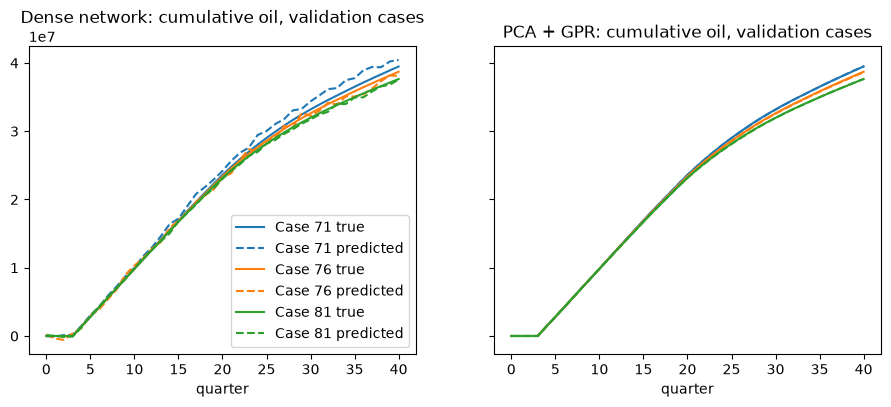

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, p) in zip(axes, [('Dense network', pred), ('PCA + GPR', pred_gpr)]):
    for i, c in enumerate([0, 5, 10]):
        ax.plot(true[c, :41], color=f'C{i}', label=f'Case {71+c} true')
        ax.plot(p[c, :41], '--', color=f'C{i}', label=f'Case {71+c} predicted')
    ax.set_title(f'{name}: cumulative oil, validation cases')
    ax.set_xlabel('quarter')
axes[0].legend()
plt.savefig(f'{OUT_DIR}/model_comparison_oil.png', dpi=200, bbox_inches='tight')
plt.show()

pd.DataFrame(results).T.round(2).to_csv(f'{OUT_DIR}/model_comparison_validation.csv')

Test cases (run once, after choosing the model)

In [17]:
BEST = 'PCA + GPR'

pred_test = predict_gpr(X[test_idx])
test_errors = errors(pred_test, Y[test_idx])
print('Test errors for', BEST)
print(pd.Series(test_errors).round(2))

Test errors for PCA + GPR
oil whole-curve %      0.09
oil at 2008 %          0.10
gas whole-curve %      0.09
gas at 2008 %          0.11
water whole-curve %    0.42
water at 2008 %        0.33
dtype: float64


## Step f: history matching

In [18]:
Y_obs = np.concatenate([oil['Observed'].values, gas['Observed'].values, water['Observed'].values])
obs_final = np.concatenate([np.full(41, Y_obs[k*41 + 40]) for k in range(3)])

rng = np.random.default_rng(42)
lo, hi = X.min(axis=0), X.max(axis=0)
candidates = rng.uniform(lo, hi, size=(100000, 4))
cand_pred = predict_gpr(candidates)

mismatch = np.mean(np.abs(cand_pred - Y_obs) / obs_final, axis=1) * 100
order = np.argsort(mismatch)

print('best 5 mismatches (%):', mismatch[order[:5]].round(3))
print(pd.DataFrame(candidates[order[:5]], columns=SETTING_COLS).round(3))

case90_mismatch = np.mean(np.abs(Y[89] - Y_obs) / obs_final) * 100
print('Case 90 itself: mismatch', round(case90_mismatch, 3), '%, settings', X[89].round(3))

best 5 mismatches (%): [0.214 0.215 0.215 0.216 0.216]
   Fault Transmissibility  Porosity Multiplier  Permeability Multiplier  \
0                   0.061                1.374                    9.682   
1                   0.101                1.373                    9.435   
2                   0.064                1.370                    9.749   
3                   0.096                1.369                    9.475   
4                   0.091                1.379                    9.632   

   Aquifer Pore Volume  
0              196.524  
1              196.051  
2              188.475  
3              193.090  
4              197.132  
Case 90 itself: mismatch 0.484 %, settings [6.1000e-02 1.3150e+00 6.0060e+00 1.3518e+02]


Choosing the 10 cases for the template

   Case  Fault Transmissibility  Porosity Multiplier  Permeability Multiplier  Aquifer Pore Volume  mismatch %
 Case 1                   0.061                1.374                    9.682              196.524       0.214
 Case 2                   0.101                1.373                    9.435              196.051       0.215
 Case 3                   0.091                1.379                    9.632              197.132       0.216
 Case 4                   0.144                1.371                    9.553              190.969       0.216
 Case 5                   0.080                1.371                    9.777              194.653       0.218
 Case 6                   0.101                1.315                    9.770               58.266       0.218
 Case 7                   0.139                1.313                    9.602               55.663       0.218
 Case 8                   0.072                1.368                    9.238              191.246       0.218
 

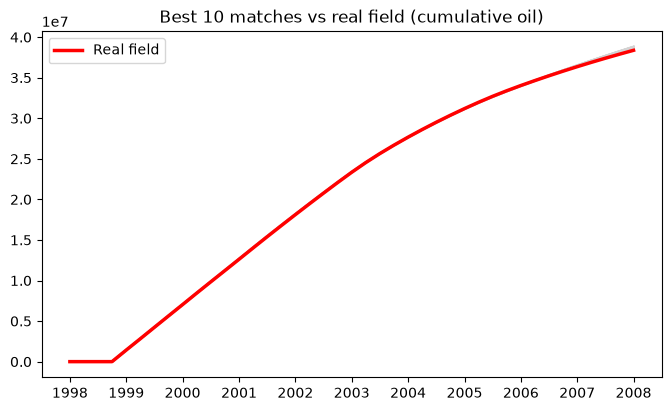

In [19]:
span = hi - lo
chosen = []
for i in order:
    z = (candidates[i] - lo) / span
    if all(np.linalg.norm(z - (candidates[j] - lo) / span) >= 0.10 for j in chosen):
        chosen.append(i)
    if len(chosen) == 10:
        break

best_settings = candidates[chosen]
best_curves = cand_pred[chosen]
best_table = pd.DataFrame(best_settings, columns=SETTING_COLS)
best_table.insert(0, 'Case', [f'Case {k+1}' for k in range(10)])
best_table['mismatch %'] = mismatch[chosen]
print(best_table.round(3).to_string(index=False))
best_table.to_csv(f'{OUT_DIR}/best10_settings.csv', index=False)

plt.figure(figsize=(8, 4.5))
for c in best_curves:
    plt.plot(oil.index, c[:41], color='lightgrey')
plt.plot(oil.index, Y_obs[:41], color='red', linewidth=2.5, label='Real field')
plt.title('Best 10 matches vs real field (cumulative oil)')
plt.legend()
plt.show()